# Exploratory analysis of the dataset

In [1]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


In [2]:
from src.dataset import load_labeled_works

df = load_labeled_works()
df.head()

,id,doi,year,title,abstract,authors,source,refs,paper_mill,peer_review,referencing,manipulation,high_label_journal
0,W2973775716,10.3233/jifs-190550,2019,Linear Diophantine fuzzy set and its applicati...,The prevailing concepts of intuitionistic fuzz...,"[A5049665961, A5077136435]",S179157397,"[W45798882, W58991120, W81336532, W84997744, W...",False,False,False,False,True
1,W2949074561,10.3233/jifs-182651,2019,A novel VIKOR method using spherical fuzzy set...,The extensions of ordinary fuzzy sets such as ...,"[A5071974529, A5014135635]",S179157397,"[W1500460861, W1668569279, W1974562332, W19775...",False,False,False,False,True
2,W2953160093,10.3233/jifs-181941,2019,Spherical fuzzy sets and its representation of...,"In this paper, we introduce spherical fuzzy se...","[A5065100059, A5077817609, A5033770251, A50498...",S179157397,"[W1505735190, W1845000206, W1980564456, W19832...",False,False,False,False,True
3,W2909139008,10.3233/jifs-169911,2019,A study on plant recognition using conventiona...,Plant species recognition from images or video...,"[A5015086258, A5012235493]",S179157397,"[W645748567, W1181899764, W1549998098, W168681...",False,False,False,False,True
4,W2945417453,10.3233/jifs-179141,2019,RETRACTED: English teaching practice based on ...,This article has been retracted. A retraction ...,"[A5024408423, A5016524175]",S179157397,"[W106215263, W288275035, W1967603002, W2008790...",True,True,True,True,True


In [3]:
print(df["refs"].apply(len).min())
print(df["refs"].apply(len).mean())
print(df["refs"].apply(len).max())

0
33.44015580043452
400


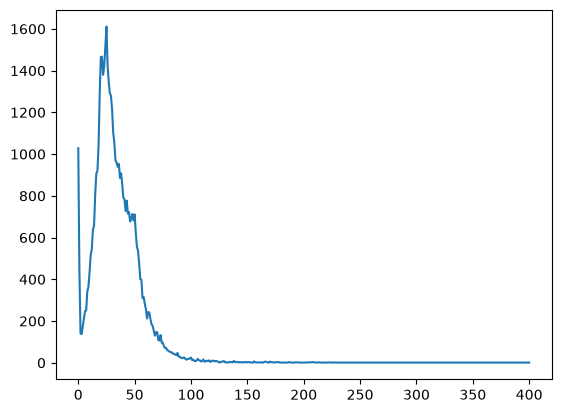

In [4]:
plt.plot(df["refs"].apply(len).value_counts().sort_index())
# plt.axis((0,100,0,100))
plt.show()


In [5]:
from typing import Callable

def filter_rows(df: pd.DataFrame) -> pd.Series:
    """Filtering criterion for accepting papers in the graph."""
    return (
        (df["abstract"] != "" )
        & (df["high_label_journal"] == False)
        & (df["abstract"].apply(lambda abstract: "retracted" not in abstract))
    )

graph_df = df[filter_rows(df)].set_index("id")

def create_graph(df: pd.DataFrame, filter_function: Callable, keep_internal_references_only: bool) -> nx.DiGraph:
    """
    Creates a networkx directed graph from the papers in the dataframe.
    Filters papers to add to the graph by using the given filtering function.
    """

    graph = nx.DiGraph()
    filtered_df = df[filter_function(df)]

    for index, row in filtered_df.iterrows():
        graph.add_node(row["id"])

    for index, row in filtered_df.iterrows():
        for ref in row["refs"]:
            if not keep_internal_references_only or ref in graph.nodes: # important choice : do we accept adding new edges with papers that are not already in the graph ? 
                graph.add_edge(row["id"], ref)

    return graph

graph = create_graph(df, filter_rows, keep_internal_references_only=True)

print(graph)

DiGraph with 605 nodes and 79 edges


In [86]:
components = list(sorted(nx.strongly_connected_components(graph), key=len, reverse=True))
print(len(list(components)))

# for cc in components:
#     print(graph.subgraph(cc))

36604


The citation graph is basically acyclic, it has no major strongly connected component. We can work with the biggest weakly connected component instead, by leaving out only a small fraction of nodes.

In [7]:
max_component = graph.subgraph(max(nx.weakly_connected_components(graph), key=len))
print(max_component)

DiGraph with 9 nodes and 8 edges


## Degree distribution

1     27510
2      5715
3      1733
4       715
5       348
      ...  
67        1
68        1
69        0
70        0
71        1
Name: count, Length: 71, dtype: int64


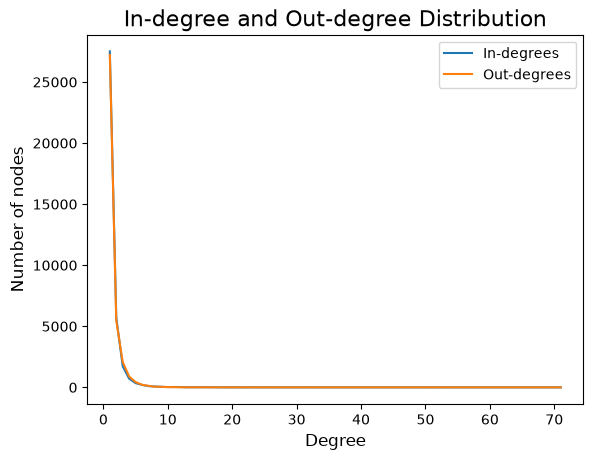

In [88]:
in_degrees: list[tuple[str, int]] = graph.in_degree
out_degrees: list[tuple[str, int]] = graph.out_degree

max_degree = max(list(in_degrees) + list(out_degrees), key=lambda degree: degree[1])[1]
degrees = pd.Series(range(1, max_degree+2))

# Convert in_degrees and out_degrees to pandas Series
in_degrees_series = pd.Series([degree[1] for degree in in_degrees]) +1 
out_degrees_series = pd.Series([degree[1] for degree in out_degrees]) +1 

# Count occurrences of each degree
in_degrees_count = in_degrees_series.value_counts().sort_index().reindex(degrees, fill_value=0)
out_degrees_count = out_degrees_series.value_counts().sort_index().reindex(degrees, fill_value=0)


print(in_degrees_count)

plt.plot(in_degrees_count, label="In-degrees")
plt.plot(out_degrees_count, label="Out-degrees")
plt.title("In-degree and Out-degree Distribution", fontsize=16)
plt.xlabel("Degree", fontsize=12)
plt.ylabel("Number of nodes", fontsize=12)
# plt.axis((5, 100, 0, 2000))

plt.legend()
plt.show()

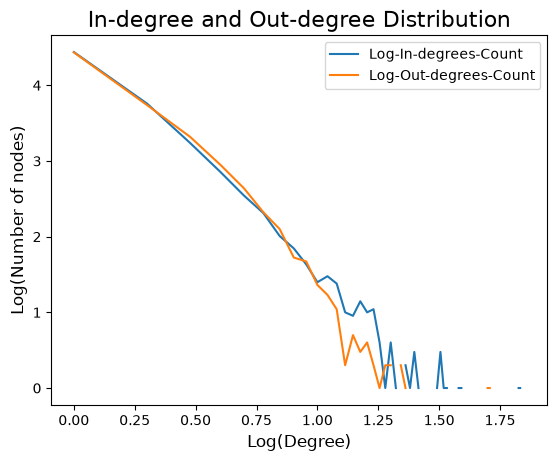

In [89]:
log_in_degrees_count = in_degrees_count.apply(np.log10)
log_out_degrees_count = out_degrees_count.apply(np.log10)
log_degrees = degrees.apply(np.log10)

plt.plot(log_degrees, log_in_degrees_count, label="Log-In-degrees-Count")
plt.plot(log_degrees, log_out_degrees_count, label="Log-Out-degrees-Count")
plt.title("In-degree and Out-degree Distribution", fontsize=16)
plt.xlabel("Log(Degree)", fontsize=12)
plt.ylabel("Log(Number of nodes)", fontsize=12)
plt.legend()
plt.show()

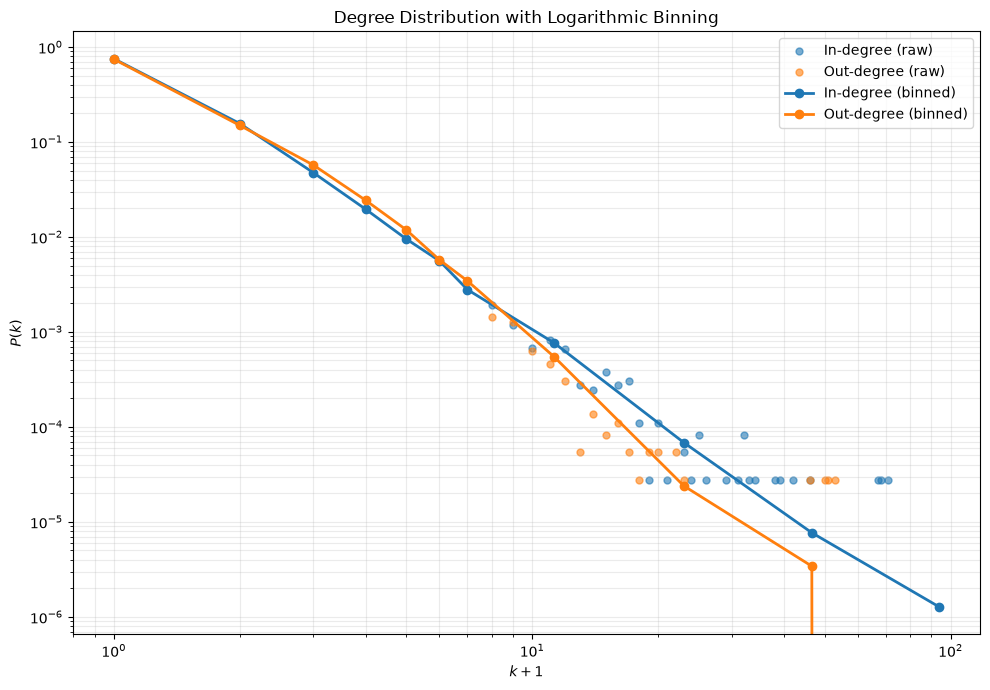

In [90]:
# ----------------------------
# Raw degree distributions
# ----------------------------

in_degree_values = np.array([degree for _, degree in in_degrees])
out_degree_values = np.array([degree for _, degree in out_degrees])

n = len(in_degree_values)

max_degree = max(
    in_degree_values.max(),
    out_degree_values.max()
)

# Count every degree, including degrees that don't occur
in_counts = (
    pd.Series(in_degree_values)
    .value_counts()
    .reindex(range(max_degree + 1), fill_value=0)
)

out_counts = (
    pd.Series(out_degree_values)
    .value_counts()
    .reindex(range(max_degree + 1), fill_value=0)
)


# ----------------------------
# Binning
# ----------------------------

# Bins are defined in u = k + 1
bin_edges = [1, 2, 3, 4, 5, 6, 7, 8, 16, 32, 64, 128]


def bin_distribution(counts, bin_edges, n):
    """
    Bin a degree distribution using the course's scheme.

    Returns:
        x: geometric mean of degrees in each bin (using k + 1)
        y: normalized count per unit bin width
    """
    x = []
    y = []

    for left, right in zip(bin_edges[:-1], bin_edges[1:]):

        # u = k + 1
        # Therefore k = u - 1
        degrees_in_bin = np.arange(left, right) - 1

        # Don't include degrees outside our actual distribution
        degrees_in_bin = degrees_in_bin[
            degrees_in_bin <= counts.index.max()
        ]

        if len(degrees_in_bin) == 0:
            continue

        # Number of nodes whose degree falls in this bin
        count = counts.loc[degrees_in_bin].sum()

        # IMPORTANT:
        # Normalize by the bin's width, NOT by the number of
        # observed degrees/nodes in the bin.
        width = right - left

        y.append(count / n / width)

        # Geometric mean of the u values covered by the bin
        u_values = np.arange(left, right)
        x.append(np.exp(np.mean(np.log(u_values))))

    return np.array(x), np.array(y)


in_bin_x, in_bin_y = bin_distribution(
    in_counts,
    bin_edges,
    n
)

out_bin_x, out_bin_y = bin_distribution(
    out_counts,
    bin_edges,
    n
)


# ----------------------------
# Raw distributions
# ----------------------------

# Raw P(k), shifted to k + 1
raw_x = np.arange(max_degree + 1) + 1

in_raw_y = in_counts.values / n
out_raw_y = out_counts.values / n


# ----------------------------
# Plot
# ----------------------------

plt.figure(figsize=(10, 7))

# Raw points
plt.scatter(
    raw_x,
    in_raw_y,
    s=25,
    alpha=0.6,
    label="In-degree (raw)"
)

plt.scatter(
    raw_x,
    out_raw_y,
    s=25,
    alpha=0.6,
    label="Out-degree (raw)"
)

# Binned distributions
plt.plot(
    in_bin_x,
    in_bin_y,
    marker="o",
    linewidth=2,
    label="In-degree (binned)"
)

plt.plot(
    out_bin_x,
    out_bin_y,
    marker="o",
    linewidth=2,
    label="Out-degree (binned)"
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel(r"$k+1$")
plt.ylabel(r"$P(k)$")
plt.title("Degree Distribution with Logarithmic Binning")

plt.legend()
plt.grid(True, which="both", alpha=0.25)

plt.tight_layout()
plt.show()

In [91]:
# report on how much of the graph is usable for text analysis
usable_abstracts = 0
nodes_number = len(graph.nodes)
df_indexed = df.set_index("id")

for node in graph.nodes:
    abstract = str(df_indexed.loc[node]["abstract"])
    if abstract != "":
        usable_abstracts += 1

assert usable_abstracts == nodes_number, "Some abstracts are missing from the nodes in the graph, so the textual analysis is not possible."

## Textual analysis 

In [14]:
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity

# A model optimized for semantic similarity
from sentence_transformers import CrossEncoder

crossencoder_model = CrossEncoder(
    "cross-encoder/ms-marco-MiniLM-L-6-v2"
)


Loading weights: 100%|██████████| 105/105 [00:00<00:00, 2763.13it/s]


1
142.94038088900197
973


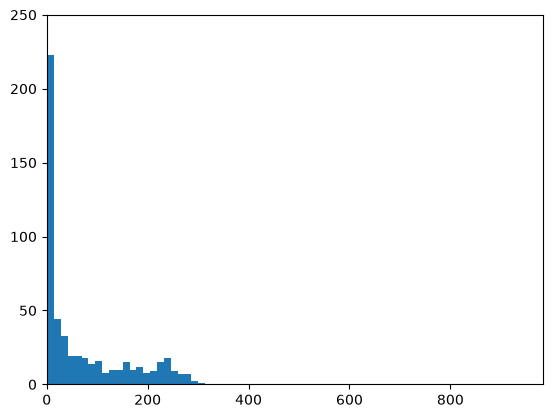

In [93]:
abstracts_word_length = df["abstract"].apply(lambda s: len(s.split(" ")))

print(abstracts_word_length.min())
print(abstracts_word_length.mean())
print(abstracts_word_length.max())

plt.hist(abstracts_word_length.value_counts().sort_index(), bins=1000)
plt.axis((0, abstracts_word_length.max()+10, 0, 250))
plt.show()


In [15]:
abstract1 = df["abstract"][0]

abstract2 = df["abstract"][2001]

score = crossencoder_model.predict([
    (abstract1, abstract2)
])

print(abstract1)
print(abstract2)
print(f"Similarity: {score[0]:.4f}")

The prevailing concepts of intuitionistic fuzzy sets (IFSs), Pythagorean fuzzy sets (PFSs) and q-rung orthopair fuzzy sets (q-ROFSs) have numerous applications in various fields from real life. Unfortunately, these theories have their own limitations related to the membership and non-membership grades. To eradicate these restrictions, we introduce the novel concept of linear Diophantine fuzzy set (LDFS) with the addition of reference parameters. This idea removes the restrictions of existing methodologies and the decision maker (DM) can freely choose the grades without any limitations. This structure also categorizes the problem by changing the physical sense of reference parameters. We present some fundamental operations on linear Diophantine fuzzy sets (LDFSs). We present geometrical interpretation for different operations of LDFSs. We also introduce the novel concepts of linear Diophantine fuzzy topological space (LDFTS) and linear Diophantine fuzzy weighted geometric aggregation (L

In [32]:
def edge_similarity_score(edge: tuple[str, str], graph_df: pd.DataFrame):
    abstract_u = graph_df.loc[edge[0]]["abstract"]
    abstract_v = graph_df.loc[edge[1]]["abstract"]
    return crossencoder_model.predict([(abstract_u, abstract_v)])

def graph_similarity_scores(graph: nx.DiGraph, graph_df: pd.DataFrame) -> dict[tuple[str,str],float]:
    """
    For each edge of the graph linking 2 papers with abstracts, computes the similarity score.
    """
    similarity_scores: dict[tuple[str,str],float] = dict()
    for edge in graph.edges:
        similarity_scores[edge] = edge_similarity_score(edge, graph_df)
    return similarity_scores

def plot_similarity_scores(similarity_scores: dict[tuple[str,str],float], label: str):
    plt.hist(np.array(list(similarity_scores.values())), bins=10, range=(-10,10))
    plt.xlabel(label)
    # plt.xlim(-1,1)
    plt.show()

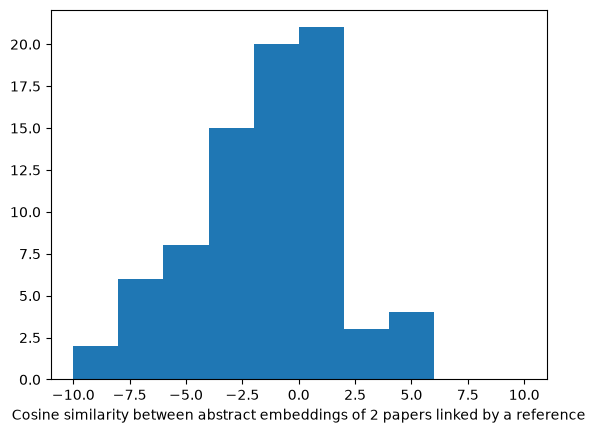

In [33]:
similarity_scores = graph_similarity_scores(graph, graph_df)
plot_similarity_scores(similarity_scores, "Cosine similarity between abstract embeddings of 2 papers linked by a reference")

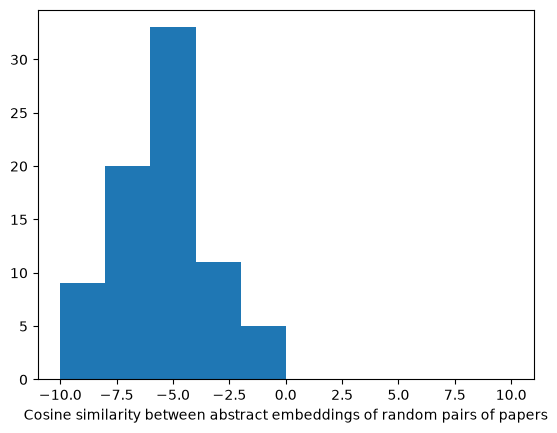

In [34]:
# first null model : similarity between randomly sampled pairs of papers
# the second null model should be a configuration model of the first graph, so the same papers are used, just different pairs

edges_count = len(graph.edges)
similarity_scores: dict[tuple[str,str],float] = dict()

for i in range(edges_count):
    node_u = np.random.choice(graph_df.index)
    node_v = np.random.choice(graph_df.index)
    false_edge = (node_u, node_v)
    if node_u == node_v or false_edge in graph.edges:
        i-=1
        continue

    similarity_scores[false_edge] = edge_similarity_score(false_edge, graph_df)

plot_similarity_scores(similarity_scores, "Cosine similarity between abstract embeddings of random pairs of papers")
   

In [112]:
# configuration_model_graph = nx.directed_edge_swap(
#     graph.copy(),
#     nswap=2*graph.number_of_edges(),
#     max_tries=100*graph.number_of_edges(),
# )

# similarity_scores = graph_similarity_scores(configuration_model_graph, graph_df)
# plot_similarity_scores(similarity_scores)

In [104]:
dataframe_name = input("Filename to save the dataframe with embeddings as : ")
# graph_df.to_parquet("dataframes/"+dataframe_name+".parquet")
graph_df.to_pickle("dataframes/"+dataframe_name+".pickle")

In [108]:
graph_df_loaded = pd.read_pickle(f"dataframes/"+dataframe_name+".pickle")
graph_df.equals(graph_df_loaded)

True